# 01. Cost Function & Loss Visualization
### Understanding How Linear Regression Measures Error (Qatar Real Estate Context)

In supervised machine learning, **Linear Regression** models the relationship between an input feature $x$ and a target value $y$ using a linear equation:

$$f_{w,b}(x) = w x + b$$

where:
- **$w$ (weight / slope):** The rate of change in $y$ per unit increase in $x$.
- **$b$ (bias / intercept):** The baseline value of $y$ when $x = 0$.

---

### What is a Cost Function?
Any values of $(w, b)$ draw a line through our data, but some lines fit much better than others. A **Cost Function** $J(w, b)$ gives us a single numerical score measuring how "wrong" the model's predictions are compared to actual ground truth values.

The goal of machine learning is to find the parameter pair $(w^*, b^*)$ that **minimizes the cost function**.

---

### Realistic Qatar Scenario: Lusail & Doha Apartment Rents
In this demo, we want to predict **monthly apartment rent in Qatari Riyals (QAR)** based on **apartment size in square meters ($m^2$)**.

In [21]:
# Step 1: Import core scientific libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configure clean visual styling
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10

## Section 1: Loading & Inspecting the Qatar Rental Dataset

We load our dataset from `data/qatar_living_rent.csv`. It contains 16 residential apartments in Doha and Lusail with their area ($m^2$) and monthly rent (QAR).

In [22]:
# Step 2: Load the dataset from CSV
df = pd.read_csv('data/qatar_living_rent.csv')

print(f"Number of apartment listings: {len(df)}")
print("\nFirst 5 listings in Doha & Lusail:")
display(df.head()) if 'display' in globals() else print(df.head())

# Extract feature x and target y as 1D NumPy arrays
x = df['area_m2'].values
y = df['monthly_rent_qar'].values
m = len(y)  # Number of training samples

Number of apartment listings: 16

First 5 listings in Doha & Lusail:
   area_m2  monthly_rent_qar
0       45              3800
1       55              4400
2       65              5100
3       75              5600
4       85              6200


## Section 2: Visualizing the Raw Data

Let's plot apartment area on the x-axis and monthly rent on the y-axis. As expected in the Qatar rental market, larger apartments generally command higher rent.

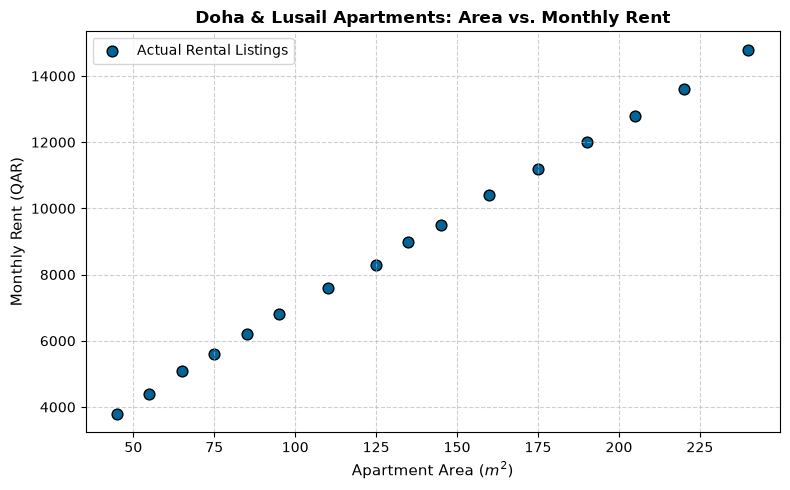

In [23]:
# Step 3: Scatter plot of the data points
plt.figure(figsize=(8, 5))
plt.scatter(x, y, color='#006699', s=60, edgecolors='black', label='Actual Rental Listings')
plt.title('Doha & Lusail Apartments: Area vs. Monthly Rent', fontsize=12, fontweight='bold')
plt.xlabel('Apartment Area ($m^2$)', fontsize=11)
plt.ylabel('Monthly Rent (QAR)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## Section 3: The Mean Squared Error (MSE) Cost Function

For each data point $i$, the model predicts:
$$\hat{y}^{(i)} = w x^{(i)} + b$$

The **residual (error)** for that single example is:
$$e^{(i)} = \hat{y}^{(i)} - y^{(i)}$$

The **Mean Squared Error (MSE)** cost function $J(w, b)$ squares each error and divides by $m$ (the number of examples):

$$J(w, b) = \frac{1}{m} \sum_{i=1}^{m} \left( f_{w,b}(x^{(i)}) - y^{(i)} \right)^2 = \frac{1}{m} \sum_{i=1}^{m} (w x^{(i)} + b - y^{(i)})^2$$

### Why divide by $m$?
Dividing by $m$ computes the average (mean) squared error across the dataset, ensuring the cost value is independent of the dataset size.

### Why square the errors?
1. **Positive Penalties:** Errors in either direction (overestimating or underestimating) become positive.
2. **Penalizes Outliers:** Large errors are penalized much more heavily than small errors ($10^2 = 100$, while $2^2 = 4$).
3. **Smooth Math:** Squaring produces a smooth parabola with a single unique minimum.

In [24]:
# Step 4: Define the MSE function J(w, b)
def compute_cost(x, y, w, b):
    """
    Compute Mean Squared Error (MSE) cost: J(w, b) = (1/m) * sum((w*x + b - y)^2).
    
    Parameters:
        x (ndarray): Feature vector of apartment sizes (m,)
        y (ndarray): Target vector of rents in QAR (m,)
        w (float): Slope parameter (weight)
        b (float): Intercept parameter (bias)
        
    Returns:
        float: Computed MSE J(w, b)
    """
    m = len(y)
    y_hat = w * x + b
    errors = y_hat - y
    cost = (1 / m) * np.sum(errors ** 2)
    return cost

## Section 4: Comparing a "Good Fit" vs. a "Bad Fit"

Let's test two candidate lines:
- **Candidate A (Good line):** $w = 55.0$ QAR/$m^2$, $b = 1350$ QAR
- **Candidate B (Bad line):** $w = 20.0$ QAR/$m^2$, $b = 8000$ QAR

We will draw vertical red dashed lines connecting each actual data point to the model's prediction. These vertical segments represent the **residuals**.

Candidate A (Good line) MSE : 32,773.4
Candidate B (Bad line)  MSE : 7,872,500.0


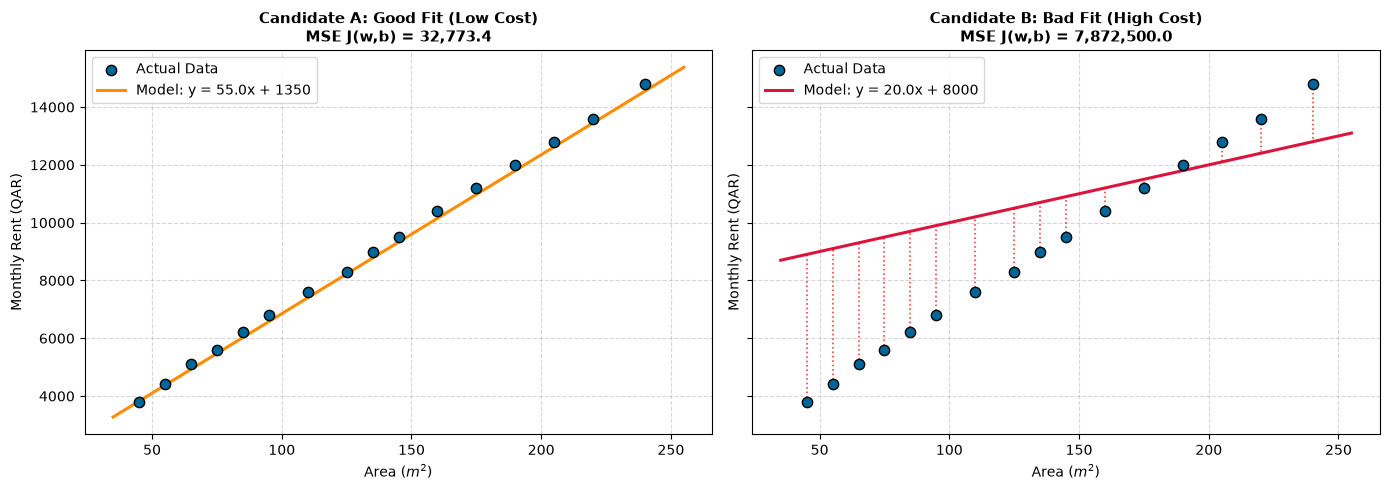

In [25]:
# Step 5: Evaluate cost for both candidate models
w_good, b_good = 55.0, 1350.0
w_bad, b_bad = 20.0, 8000.0

cost_good = compute_cost(x, y, w_good, b_good)
cost_bad = compute_cost(x, y, w_bad, b_bad)

print(f"Candidate A (Good line) MSE : {cost_good:,.1f}")
print(f"Candidate B (Bad line)  MSE : {cost_bad:,.1f}")

# Visualize residual comparison side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

models = [
    (w_good, b_good, "Candidate A: Good Fit (Low Cost)", cost_good, 'darkorange'),
    (w_bad, b_bad, "Candidate B: Bad Fit (High Cost)", cost_bad, 'crimson')
]

x_line = np.linspace(35, 255, 100)

for ax, (w_val, b_val, title, cost_val, line_color) in zip(axes, models):
    # Plot actual listings
    ax.scatter(x, y, color='#006699', s=55, edgecolors='k', zorder=3, label='Actual Data')
    
    # Plot model prediction line
    y_line = w_val * x_line + b_val
    ax.plot(x_line, y_line, color=line_color, linewidth=2.2, label=f'Model: y = {w_val}x + {b_val:.0f}')
    
    # Draw red dashed residual lines from data point to regression line
    for xi, yi in zip(x, y):
        pred_i = w_val * xi + b_val
        ax.plot([xi, xi], [yi, pred_i], color='red', linestyle=':', alpha=0.75, linewidth=1.2)
        
    ax.set_title(f"{title}\nMSE J(w,b) = {cost_val:,.1f}", fontsize=11, fontweight='bold')
    ax.set_xlabel('Area ($m^2$)')
    ax.set_ylabel('Monthly Rent (QAR)')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper left')

plt.tight_layout()
plt.show()

## Section 5: Visualizing Cost vs. Slope $w$ (1D Cost Curve)

To see how the cost changes as a function of the slope $w$, let's fix $b = 1350$ QAR and evaluate $J(w)$ across a range of slope values from 25 to 85 QAR/$m^2$.

Notice that the curve is a **U-shaped parabola** with a clear global minimum. The lowest point represents the slope that minimizes squared errors for this intercept.

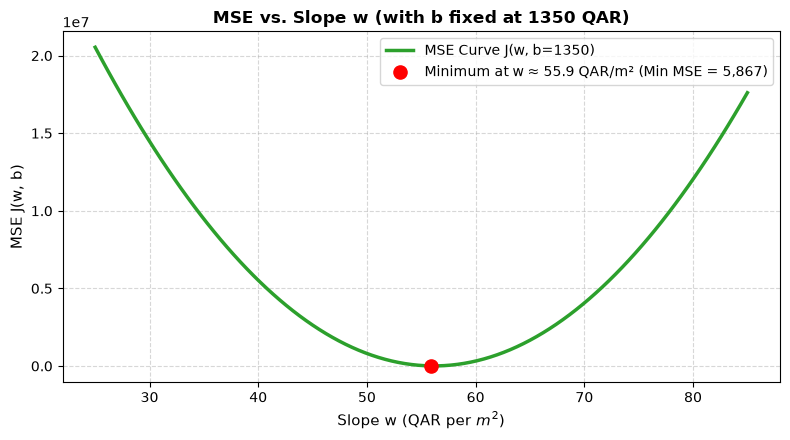

In [26]:
# Step 6: 1D cost curve visualization
b_fixed = 1350.0
w_range = np.linspace(25, 85, 100)
costs_1d = [compute_cost(x, y, w_val, b_fixed) for w_val in w_range]

# Find the slope that gives minimum cost in this slice
best_idx = np.argmin(costs_1d)
best_w = w_range[best_idx]
min_cost = costs_1d[best_idx]

plt.figure(figsize=(8, 4.5))
plt.plot(w_range, costs_1d, color='#2ca02c', linewidth=2.5, label='MSE Curve J(w, b=1350)')
plt.scatter([best_w], [min_cost], color='red', s=90, zorder=4, 
            label=f'Minimum at w ≈ {best_w:.1f} QAR/m² (Min MSE = {min_cost:,.0f})')

plt.title('MSE vs. Slope w (with b fixed at 1350 QAR)', fontsize=12, fontweight='bold')
plt.xlabel('Slope w (QAR per $m^2$)', fontsize=11)
plt.ylabel('MSE J(w, b)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## Section 6: Key Takeaways

1. **Regression Model:** $\hat{y} = w x + b$. For Doha rentals, $w$ is the marginal rent per additional square meter, while $b$ is the base rent for an apartment.
2. **Residuals:** Each point has an error $e = \hat{y} - y$.
3. **MSE Cost Function:** $J(w, b) = \frac{1}{m} \sum e_i^2$. It averages the squared errors, summarizing model performance into a single number.
4. **Convexity:** The MSE cost curve is a smooth parabola with a single unique minimum.
5. **Next Step:** In Notebook 02 and 03, we will use **Gradient Descent** to automatically navigate downhill along this curve to discover the optimal $(w^*, b^*)$.